# 04 — Anomaly detection and development evaluation

**Question:** Do the temporal features from Notebook 03 help distinguish annotated departures on other recordings, and what alert burden do they create?

We compare **eight level departures (Set A)** with **all 19 features (Set B)** using two simple detectors. Each detector calculates a score; a separate set of recordings supplies a cutoff; a short persistence rule converts scores into alerts. These are different operations and are evaluated separately.

This is a **development experiment with training annotations**, not an automatic diagnosis system. Annotations identify initial candidate-normal examples in fitting and cutoff-calibration recordings. They are never model inputs. A new recording supplies only its first fixed 60 seconds for its local sensor medians, without consulting labels. Its later annotations are used retrospectively to assess the frozen decisions.

The eight reserved experiments remain unopened. All recordings come from one testbed. Results describe transfer between its experiments, not future deployment or generalisation between companies.

**Scope of this revision.** The former empirical-rank score saturated at its calibrated cutoff and could not issue alerts. It is replaced by an unbounded median/IQR departure score. A timestamp-resolution bug in feature gap checks is also corrected. The feature definitions, fitting populations, folds, Isolation Forest settings, cutoff percentiles and alert rules are preserved; this is not a search for a better-looking policy.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest

from ts_anomaly.skab import METRICS, load_development
from ts_anomaly.features import engineer_recording
from ts_anomaly.detection import fit_departure_reference, departure_scores, calibrate_threshold, causal_alerts
from ts_anomaly.evaluation import label_windows, point_metrics, episode_metrics, observed_episodes

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
settings = json.loads((ROOT / 'configs/skab.json').read_text())
feature_settings = settings['features']
baseline_settings = settings['baselines']
experiment = settings['detection']
OUT = ROOT / 'outputs/skab_detection'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 14)
recordings, annotations = load_development(ROOT / 'data/skab', settings)
manifest = pd.DataFrame(settings['files'])
development_ids = manifest.loc[manifest.partition.eq('development'), 'recording_id'].tolist()
reserved_ids = set(manifest.loc[manifest.partition.eq('reserved_test'), 'recording_id'])
assert set(development_ids) == set(annotations)
assert reserved_ids.isdisjoint(recordings)
print(f'{len(development_ids)} development recordings; {len(reserved_ids)} reserved recordings not opened.')
print('Source commit:', settings['source_commit'])
print('Python:', sys.version.split()[0], '| scikit-learn:', version('scikit-learn'))

Matplotlib is building the font cache; this may take a moment.


26 development recordings; 8 reserved recordings not opened.
Source commit: b2c0d46c2971dcbfe71e26087b6d231998bb91c2
Python: 3.13.2 | scikit-learn: 1.9.1


## 1. Information boundaries: three roles, three different jobs

| Operation | Permitted information | What is calculated? |
|---|---|---|
| Local sensor calibration | First 60 elapsed seconds of each recording, without annotations | The eight reference medians used by Notebook 03; 180 seconds is a separate sensitivity experiment |
| Detector fitting | Complete post-180-second feature vectors before the first positive anomaly **or changepoint** annotation, in fitting recordings only | Feature medians and interquartile ranges, or isolation trees |
| Cutoff calibration | The same initial candidate-normal definition, in different recordings | The 95th and 99th percentiles of their frozen detector scores |
| Development assessment | Other whole recordings, after 180 seconds | Frozen scores and alerts; labels consulted for assessment only |

We assign recordings in numeric filename order, round-robin within each intervention family, to three groups. Each group is assessed once; the other two groups have separate fitting and cutoff-calibration roles. The assignment uses file identities, not observed detection performance. Families balance the groups and are not predictors.

This is **annotation-assisted normal-reference training**. It does not assume that every label-zero recovery interval is healthy. The pre-annotation portion is only *candidate normal*. In an operational application, its equivalent would require credible commissioning or maintenance evidence.

The separate normal file is not used here: Notebook 02 found source overlap with `other/5`, and its operating levels differ from many experiments. `other/5` can remain in a development group because that overlapping separate file contributes no fitting or cutoff-calibration rows.

In [2]:
assert experiment['folds'] == 3  # Three distinct roles define this experiment.
fold_rows = []
for family in ['other', 'valve1', 'valve2']:
    identifiers = [name for name in development_ids if name.startswith(family + '/')]
    identifiers.sort(key=lambda name: int(name.split('/')[1]))
    for position, name in enumerate(identifiers):
        fold_rows.append({'recording_id': name, 'family': family,
                          'fold': position % experiment['folds']})
folds = pd.DataFrame(fold_rows).set_index('recording_id')
assert set(folds.index) == set(development_ids)
roles = []
for fold in range(3):
    fit_ids = folds.index[folds.fold.eq((fold + 1) % 3)].tolist()
    cutoff_ids = folds.index[folds.fold.eq((fold + 2) % 3)].tolist()
    assess_ids = folds.index[folds.fold.eq(fold)].tolist()
    assert set(fit_ids).isdisjoint(cutoff_ids + assess_ids)
    assert set(cutoff_ids).isdisjoint(assess_ids)
    roles.append({'assessment_fold': fold, 'fit_recordings': ', '.join(fit_ids),
                  'cutoff_recordings': ', '.join(cutoff_ids),
                  'assessment_recordings': ', '.join(assess_ids)})
role_table = pd.DataFrame(roles)
display(pd.crosstab(folds.family, folds.fold))
display(folds.sort_values(['fold', 'family']).reset_index())
display(pd.DataFrame({'assessment_fold': [0, 1, 2], 'fit_fold': [1, 2, 0], 'cutoff_fold': [2, 0, 1]}))
folds.to_csv(OUT / 'recording_folds.csv')
role_table.to_csv(OUT / 'information_roles.csv', index=False)

fold,0,1,2
family,,,
other,4,4,3
valve1,4,4,4
valve2,1,1,1


,recording_id,family,fold
0,other/1,other,0
1,other/5,other,0
2,other/9,other,0
3,other/13,other,0
4,valve1/0,valve1,0
5,valve1/4,valve1,0
6,valve1/8,valve1,0
7,valve1/12,valve1,0
8,valve2/0,valve2,0
9,other/2,other,1


,assessment_fold,fit_fold,cutoff_fold
0,0,1,2
1,1,2,0
2,2,0,1


## 2. Reuse the frozen feature definitions and expose unavailable cases

Features are rebuilt with the Notebook 03 functions, with timestamp-resolution-independent gap checks. No detector sees a recording identifier, family, elapsed intervention schedule, anomaly label or changepoint label. The local calibration period is fixed before labels are consulted.

All primary comparisons start on five-second targets wholly after elapsed 180 seconds. Set A and Set B use the **same complete 19-feature rows for fitting and cutoff calibration**. In assessment we preserve each set's own availability, and also evaluate both on the common Set B availability. For the common comparison, missing timestamps reset **both alert histories**, not only the metric denominator.

An unavailable score is not a zero score or a declaration of normality. Calibration failure and collection gaps remain visible. The 180-second sensitivity comparison uses the same endpoints and reports its own additional support losses.

In [3]:
features, calibration_rows, support_rows = {}, [], []
step = pd.Timedelta(baseline_settings['aggregation_interval'])
for duration in baseline_settings['calibration_seconds']:
    for name in development_ids:
        values, support, references = engineer_recording(
            recordings[name], list(METRICS), feature_settings['slope_measurements'],
            feature_settings['variability_measurements'], feature_settings['history_measurements'],
            calibration_seconds=duration, frequency=baseline_settings['aggregation_interval'],
            min_count=baseline_settings['minimum_bin_observations'], window=feature_settings['window'],
            minimum_occupancy=baseline_settings['minimum_occupancy'],
            max_gap=settings['gap_threshold'], nominal_interval=settings['nominal_interval'])
        boundary = recordings[name].timestamp.iloc[0] + pd.Timedelta(
            seconds=experiment['assessment_start_seconds'])
        features[duration, name] = values.loc[values.index - step >= boundary]
        calibration_rows.append(references.assign(recording_id=name))
        selected_support = support.loc[support.timestamp.isin(features[duration, name].index)]
        reasons = selected_support.groupby(['feature', 'reason']).size().rename('endpoints').reset_index()
        support_rows.append(reasons.assign(recording_id=name, calibration_seconds=duration))
calibration = pd.concat(calibration_rows, ignore_index=True)
support_reasons = pd.concat(support_rows, ignore_index=True)
feature_sets = {'A_level': [f'{name}__level' for name in METRICS],
                'B_expanded': list(features[60, development_ids[0]].columns)}
assert len(feature_sets['A_level']) == 8 and len(feature_sets['B_expanded']) == 19
calibration.to_csv(OUT / 'local_calibration.csv', index=False)
support_reasons.to_csv(OUT / 'feature_support_reasons.csv', index=False)

In [4]:
reference_masks, window_labels, native_labels = {}, {}, {}
availability_rows = []
for name in development_ids:
    labels = annotations[name].set_index('timestamp')
    native_labels[name] = labels.anomaly
    marked = labels.anomaly.eq(1) | labels.changepoint.eq(1)
    first_mark = labels.index[marked][0] if marked.any() else labels.index[-1] + pd.Timedelta('1s')
    window_labels[name] = label_windows(labels.anomaly, features[60, name].index,
                                       frequency=step, min_count=baseline_settings['minimum_bin_observations'])
    for duration in baseline_settings['calibration_seconds']:
        values = features[duration, name]
        complete = values.notna().all(axis=1)
        reference_masks[duration, name] = complete & (values.index <= first_mark)
        for set_name, columns in feature_sets.items():
            available = values[columns].notna().all(axis=1)
            availability_rows.append({'recording_id': name, 'calibration_seconds': duration,
                                      'feature_set': set_name, 'requested': len(values),
                                      'available': int(available.sum()),
                                      'availability': available.mean(),
                                      'candidate_normal_rows': int(reference_masks[duration, name].sum()),
                                      'first_annotation': first_mark})
availability = pd.DataFrame(availability_rows)
display(availability.groupby(['calibration_seconds', 'feature_set'])[
    ['requested', 'available']].sum())
display(availability.loc[availability.candidate_normal_rows.eq(0),
                         ['recording_id', 'calibration_seconds', 'feature_set', 'available']])
print('Pure / mixed / unsupported evaluation bins:')
display(pd.concat(window_labels).status.value_counts().rename('endpoints').to_frame())
availability.to_csv(OUT / 'availability_by_recording.csv', index=False)

requested  available
calibration_seconds feature_set                      
60                  A_level           5150       4885
                    B_expanded        5150       4864
180                 A_level           5150       4743
                    B_expanded        5150       4727

,recording_id,calibration_seconds,feature_set,available
12,other/13,60,A_level,0
13,other/13,60,B_expanded,0
14,other/13,180,A_level,0
15,other/13,180,B_expanded,0
20,other/2,60,A_level,142
21,other/2,60,B_expanded,137
22,other/2,180,A_level,0
23,other/2,180,B_expanded,0


Pure / mixed / unsupported evaluation bins:


,endpoints
status,
pure,5010
insufficient_labels,100
mixed,40


**Reading the support audit.** Zero candidate-normal rows means that a recording contributes nothing when it has a fitting or cutoff-calibration role. It is still assessed when held out. With 60-second local calibration, `other/13` has no complete level reference and `other/2` has no eligible post-180-second pre-annotation training rows because of its gap. The latter can still supply later assessment scores. Complete numerical outputs retain both cases.

Five-second label bins are retrospective summaries: a bin needs at least four labels and must contain only zeros or only ones. Mixed transition bins remain unknown for point metrics. They do **not** reset operational alerts; only unavailable features do that.

## 3. Fit two small detectors; calibrate their cutoffs on different recordings

**Maximum median/IQR departure.** For each feature, calculate its median and interquartile range (IQR = 75th minus 25th percentile) from the permitted fitting vectors. Freeze both. At assessment time:

\[
D_j(t)=\frac{|x_j(t)-m_j|}{Q_{.75,j}-Q_{.25,j}},\qquad S(t)=\max_j D_j(t).
\]

A component of 0 means the fitted median; 1 means one fitted IQR away. Larger departures keep growing beyond the largest fitting value. The maximum asks: *does any individual feature depart substantially from its fitted centre, relative to its ordinary spread?* It does not model relationships between features. Components are dimensionless magnitudes, **not probabilities, normal-distribution z-scores or a measure of fault severity**. The spread is fitted across candidate-normal training recordings, not inferred from the new recording or its labels.

A zero IQR, including tied but nonconstant training data, makes that feature unsupported. Its component and the complete-vector score remain unavailable; no epsilon, fallback scale or silent feature removal is used. The reference audit below exposes every fitted median, spread and support flag. Positive IQR permits calculation but does not prove that a pooled reference transfers across operating regimes.

**Why replace empirical rarity?** The previous smoothed rank score had maximum $1-2/(n+1)$ for $n$ fitting rows. Its 95th/99th-percentile cutoffs reached that ceiling, while alerts required strict exceedance. No value could trigger an alert. The new score retains departure magnitude; we preserve the strict `>` comparison and the original cutoff/persistence settings. This correction does not guarantee useful detection or acceptable alert burden.

**Isolation Forest.** Random trees isolate feature vectors; short average isolation paths produce higher scores. We retain 200 trees, at most 256 fitting examples per tree, and the fixed seed. Scores are `-score_samples`; scikit-learn's default binary cutoff is not used. It can represent combinations but does not itself identify a physical fault. No additional scaler or feature selection is fitted.

The primary cutoff remains the 99th percentile of separate candidate-normal calibration scores, with the 95th percentile as sensitivity. Adding features increases opportunities for large maxima, so each set receives its own cutoff. **Neither percentile guarantees a 1% or 5% future false-alert rate**, especially with dependence and transfer between recordings. [Isolation Forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html), [novelty detection assumptions](https://scikit-learn.org/stable/modules/outlier_detection.html).

In [5]:
# A hand-checkable example: all values are beyond the fitted maximum of 6.
example_reference = fit_departure_reference(pd.DataFrame({'x': [0., 2., 4., 6.]}))
example_values = pd.DataFrame({'x': [9., 15., 33.]})
example_scores, _ = departure_scores(example_reference, example_values)
display(example_values.assign(fitted_median=3., fitted_iqr=3.,
    former_rank_ceiling=1 - 2 / 5, median_iqr_departure=example_scores))
print('Moving farther from the fitted median increases the new score: 2, 4, 10 IQRs.')

,x,fitted_median,fitted_iqr,former_rank_ceiling,median_iqr_departure
0,9.0,3.0,3.0,0.6,2.0
1,15.0,3.0,3.0,0.6,4.0
2,33.0,3.0,3.0,0.6,10.0


Moving farther from the fitted median increases the new score: 2, 4, 10 IQRs.


In [6]:
training_values, scoring, component_tables = {}, {}, []
model_rows, threshold_rows, departure_reference_rows = [], [], []
for duration in baseline_settings['calibration_seconds']:
    for fold in range(3):
        fit_ids = folds.index[folds.fold.eq((fold + 1) % 3)].tolist()
        cutoff_ids = folds.index[folds.fold.eq((fold + 2) % 3)].tolist()
        assess_ids = folds.index[folds.fold.eq(fold)].tolist()
        fit_all = pd.concat([features[duration, name].loc[reference_masks[duration, name]]
                             for name in fit_ids], keys=fit_ids, names=['recording_id'])
        cutoff_all = pd.concat([features[duration, name].loc[reference_masks[duration, name]]
                                for name in cutoff_ids], keys=cutoff_ids, names=['recording_id'])
        assert len(fit_all) and len(cutoff_all)
        for set_name, columns in feature_sets.items():
            fit_values, cutoff_values = fit_all[columns], cutoff_all[columns]
            departure = fit_departure_reference(fit_values)
            departure_reference_rows.append(departure.reset_index().assign(
                calibration_seconds=duration, fold=fold, feature_set=set_name))
            forest = IsolationForest(n_estimators=experiment['isolation_trees'],
                                     max_samples=experiment['isolation_max_samples'],
                                     random_state=experiment['primary_seed'], n_jobs=1)
            forest.fit(fit_values)
            departure_cutoff, _ = departure_scores(departure, cutoff_values)
            forest_cutoff = pd.Series(-forest.score_samples(cutoff_values), index=cutoff_values.index)
            training_values[duration, fold, set_name] = fit_values
            for method, calibration_scores in [('departure', departure_cutoff),
                                                       ('isolation', forest_cutoff)]:
                model_rows.append({'calibration_seconds': duration, 'fold': fold,
                                   'feature_set': set_name, 'method': method, 'fit_rows': len(fit_values),
                                   'fit_recordings_contributing': fit_values.index.get_level_values(0).nunique(),
                                   'cutoff_rows': len(cutoff_values),
                                   'cutoff_recordings_contributing': cutoff_values.index.get_level_values(0).nunique(),
                                   'constant_fit_features': ', '.join(fit_values.columns[fit_values.nunique().le(1)])})
                for quantile in experiment['threshold_quantiles']:
                    threshold_rows.append({'calibration_seconds': duration, 'fold': fold,
                                           'feature_set': set_name, 'method': method,
                                           **calibrate_threshold(calibration_scores, quantile).to_dict()})
            for name in assess_ids:
                values = features[duration, name][columns]
                departure_score, components = departure_scores(departure, values)
                forest_score = pd.Series(np.nan, index=values.index, name='score')
                finite = values.notna().all(axis=1)
                if finite.any():
                    forest_score.loc[finite] = -forest.score_samples(values.loc[finite])
                scoring[duration, name, set_name, 'departure'] = departure_score
                scoring[duration, name, set_name, 'isolation'] = forest_score
                component_tables.append(components.assign(recording_id=name, calibration_seconds=duration,
                                                           feature_set=set_name))
model_audit = pd.DataFrame(model_rows)
thresholds = pd.DataFrame(threshold_rows)
display(model_audit.loc[model_audit.calibration_seconds.eq(60)].round(4))
display(thresholds.loc[thresholds.calibration_seconds.eq(60) & thresholds['quantile'].eq(.99),
                      ['fold', 'feature_set', 'method', 'threshold', 'rows', 'distinct_scores',
                       'exceeded_fraction', 'threshold_at_maximum']].round(5))
model_audit.to_csv(OUT / 'model_fitting_audit.csv', index=False)
thresholds.to_csv(OUT / 'threshold_calibration.csv', index=False)
departure_references = pd.concat(departure_reference_rows, ignore_index=True)
display(departure_references.groupby(['calibration_seconds', 'feature_set']).agg(
    fitted_feature_references=('feature', 'size'), supported=('supported', 'sum'),
    minimum_distinct=('distinct', 'min')))
display(departure_references.loc[~departure_references.supported])
departure_references.to_csv(OUT / 'departure_references.csv', index=False)


,calibration_seconds,fold,feature_set,method,fit_rows,fit_recordings_contributing,cutoff_rows,cutoff_recordings_contributing,constant_fit_features
0,60,0,A_level,departure,665,8,663,8,
1,60,0,A_level,isolation,665,8,663,8,
2,60,0,B_expanded,departure,665,8,663,8,
3,60,0,B_expanded,isolation,665,8,663,8,
4,60,1,A_level,departure,663,8,663,8,
5,60,1,A_level,isolation,663,8,663,8,
6,60,1,B_expanded,departure,663,8,663,8,
7,60,1,B_expanded,isolation,663,8,663,8,
8,60,2,A_level,departure,663,8,665,8,
9,60,2,A_level,isolation,663,8,665,8,


,fold,feature_set,method,threshold,rows,distinct_scores,exceeded_fraction,threshold_at_maximum
1,0,A_level,departure,11.33717,663,624,0.01056,False
3,0,A_level,isolation,0.58564,663,663,0.01056,False
5,0,B_expanded,departure,11.33717,663,635,0.01056,False
7,0,B_expanded,isolation,0.55016,663,663,0.01056,False
9,1,A_level,departure,21.61259,663,577,0.01056,False
11,1,A_level,isolation,0.59832,663,663,0.01056,False
13,1,B_expanded,departure,21.66133,663,624,0.01056,False
15,1,B_expanded,isolation,0.56378,663,663,0.01056,False
17,2,A_level,departure,14.57703,665,564,0.01053,False
19,2,A_level,isolation,0.55625,665,665,0.01053,False


fitted_feature_references  supported  \
calibration_seconds feature_set                                         
60                  A_level                             24         24   
                    B_expanded                          57         57   
180                 A_level                             24         24   
                    B_expanded                          57         57   

                                 minimum_distinct  
calibration_seconds feature_set                    
60                  A_level                    74  
                    B_expanded                 74  
180                 A_level                    54  
                    B_expanded                 54

,feature,median,iqr,observations,distinct,supported,calibration_seconds,fold,feature_set


**Observed cutoff behaviour.** Each primary fit/cutoff population contains about 663–665 complete vectors from eight contributing recordings. All 162 fitted feature references across both calibration durations, folds and feature sets have positive IQRs. The exported reference table retains every median, IQR, count and support flag.

The departure method's primary 99th-percentile cutoffs range from **11.34 to 21.66 fitted IQRs**, with about **1.05%** of calibration scores strictly above them. None equals the observed calibration maximum, and the score has no finite ceiling. These large and varying cutoffs also warn that one pooled reference may transfer poorly between operating conditions.

`threshold_at_maximum` now describes the largest *observed calibration score*, not a mathematical upper bound. Neither positive spread nor a 1% calibration exceedance guarantees reliable detection on another recording. These dependent windows come from eight runs; extreme percentiles have little tail support. Very small positive spreads can magnify small physical changes, so a large dimensionless score is not a claim of severe damage.

## 4. Convert scores into decisions without backdating

We compare an immediate rule with a rule requiring **three consecutive available five-second scores above the cutoff**. The latter issues its first alert at the third endpoint. Below-cutoff scores, unavailable features and gaps reset the run. There is no cooldown, event merging or retrospective filling of an annotated episode.

Evaluation has several complementary views:

- **Ranking:** average precision (AP), computed separately per recording on pure-label common bins. A constant-score comparator has AP equal to that recording's positive-label fraction. AP needs both classes; it is undefined for unavailable recordings, which remain in coverage counts.
- **Point decisions:** precision and recall without point adjustment, on the stated eligible observations. We also report positive-bin recall counting unavailable decisions as undetected.
- **Observed episodes:** only fully observed positive runs have complete onset/end evidence. Detection requires a *new alert start* within the episode; a standing alarm cannot claim a later episode. Delay is from the first positive native label to that actual alert endpoint. Gap-censored pieces are listed separately, not invented as complete incidents.
- **Burden:** new alerts at label-zero times per observed, monitored label-zero hour, plus the fraction of such time spent in alert. A label-negative alert is not proven false: annotations may be incomplete.

Exposure uses actual timestamps. No time is credited across a collection gap; decisions hold for at most five seconds. Mixed label boundaries and uncertain alert-time labels are reported explicitly. We do not extrapolate these short experiments into a production daily alert rate.

[Average precision definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html); [Kim et al., AAAI 2022: risks of point-adjusted evaluation](https://arxiv.org/abs/2109.05257).

In [7]:
cutoffs = thresholds.set_index(['calibration_seconds', 'fold', 'feature_set', 'method', 'quantile']).threshold
metric_rows, event_tables, decision_tables = [], [], []
for (duration, name, set_name, method), scores in scoring.items():
    fold = int(folds.loc[name, 'fold'])
    common = features[duration, name].notna().all(axis=1)
    labels = window_labels[name].label
    for population in ['common', 'own']:
        # Common support changes the decision stream itself, not only metric selection.
        stream = scores.where(common) if population == 'common' else scores
        for quantile in experiment['threshold_quantiles']:
            threshold = cutoffs.loc[duration, fold, set_name, method, quantile]
            for consecutive in experiment['consecutive_windows']:
                decisions = causal_alerts(stream, threshold, consecutive, frequency=step)
                point = point_metrics(labels, stream, decisions.alarm)
                episode, events = episode_metrics(native_labels[name], decisions, frequency=step,
                                                   max_gap=settings['gap_threshold'])
                identity = {'recording_id': name, 'family': folds.loc[name, 'family'], 'fold': fold,
                            'calibration_seconds': duration, 'feature_set': set_name, 'method': method,
                            'population': population, 'quantile': quantile, 'consecutive': consecutive}
                metric_rows.append({**identity, **point.to_dict(), **episode.to_dict()})
                event_tables.append(events.assign(**identity))
                decision_tables.append(decisions.assign(score=stream, label=labels, threshold=threshold,
                                                         **identity))
metrics = pd.DataFrame(metric_rows)
events = pd.concat(event_tables, ignore_index=True)
decisions = pd.concat(decision_tables).reset_index()
metrics.to_csv(OUT / 'metrics_by_recording.csv', index=False)
events.to_csv(OUT / 'observed_episode_results.csv', index=False)
decisions.to_csv(OUT / 'scores_and_decisions.csv.gz', index=False)
pd.concat(component_tables).reset_index().to_csv(OUT / 'departure_components.csv.gz', index=False)
print('Every development recording is assessed once per experimental specification.')
assert metrics.groupby(['calibration_seconds', 'feature_set', 'method', 'population',
                        'quantile', 'consecutive']).recording_id.nunique().eq(26).all()

Every development recording is assessed once per experimental specification.


## 5. Compare feature sets on identical available observations

Each recording contributes one AP value, rather than allowing a long recording to dominate a pooled metric. Missing AP is excluded from the mean **and counted**. Counts, monitoring availability and whole-recording outcomes are reported alongside it. There is no IID confidence interval over temporally dependent rows, and raw scores from independently fitted folds are not pooled into one global ranking.

The paired plot compares Set A and Set B on the same common bins. A point above the diagonal favours the expanded features for ranking in that recording. This does not establish a useful cutoff or acceptable alert burden.

recordings  available_recordings  mean_AP  median_AP  \
method    feature_set                                                         
departure A_level              26                    25    0.856      0.929   
          B_expanded           26                    25    0.847      0.918   
isolation A_level              26                    25    0.811      0.881   
          B_expanded           26                    25    0.771      0.846   

                       minimum_AP  maximum_AP  mean_constant_score_AP  
method    feature_set                                                  
departure A_level           0.247       1.000                   0.412  
          B_expanded        0.252       1.000                   0.412  
isolation A_level           0.235       0.993                   0.412  
          B_expanded        0.282       0.964                   0.412

count   mean
family method    feature_set              
other  departure A_level         10  0.906
                 B_expanded      10  0.906
       isolation A_level         10  0.868
                 B_expanded      10  0.807
valve1 departure A_level         12  0.805
                 B_expanded      12  0.781
       isolation A_level         12  0.744
                 B_expanded      12  0.712
valve2 departure A_level          3  0.889
                 B_expanded       3  0.911
       isolation A_level          3  0.886
                 B_expanded       3  0.884

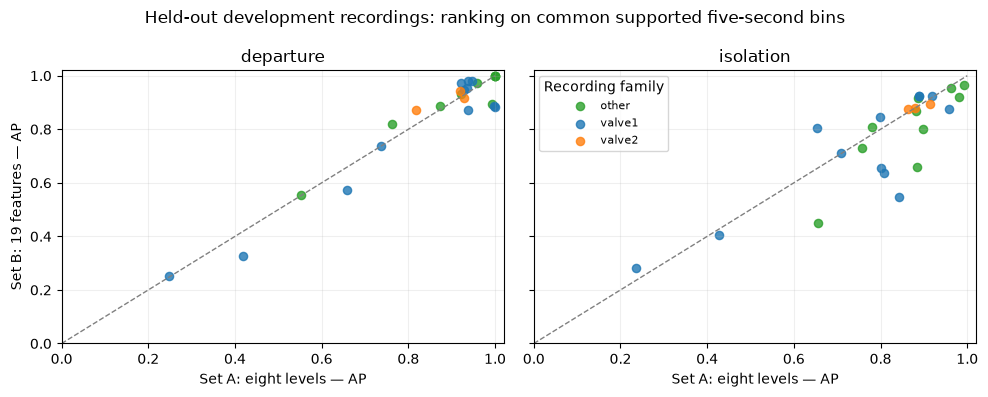

In [8]:
primary = metrics.loc[metrics.calibration_seconds.eq(60) & metrics.population.eq('common')
                      & metrics['quantile'].eq(experiment['primary_quantile'])].copy()
ranking = primary.loc[primary.consecutive.eq(1)].copy()
ranking['constant_score_AP'] = ranking.positive_common / ranking.common.replace(0, np.nan)
ranking_summary = ranking.groupby(['method', 'feature_set']).agg(
    recordings=('recording_id', 'size'), available_recordings=('average_precision', 'count'),
    mean_AP=('average_precision', 'mean'), median_AP=('average_precision', 'median'),
    minimum_AP=('average_precision', 'min'), maximum_AP=('average_precision', 'max'),
    mean_constant_score_AP=('constant_score_AP', 'mean'))
display(ranking_summary.round(3))
display(ranking.groupby(['family', 'method', 'feature_set']).average_precision.agg(['count', 'mean']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, method in zip(axes, ['departure', 'isolation']):
    paired = ranking.loc[ranking.method.eq(method)].pivot(index='recording_id', columns='feature_set',
                                                          values='average_precision')
    for family, colour in [('other', 'tab:green'), ('valve1', 'tab:blue'), ('valve2', 'tab:orange')]:
        selected = paired.loc[paired.index.str.startswith(family + '/')]
        ax.scatter(selected.A_level, selected.B_expanded, label=family, color=colour, s=35, alpha=.8)
    ax.plot([0, 1], [0, 1], '--', color='grey', linewidth=1)
    ax.set(title=method, xlabel='Set A: eight levels — AP', xlim=(0, 1.02), ylim=(0, 1.02))
axes[0].set_ylabel('Set B: 19 features — AP')
axes[1].legend(title='Recording family', fontsize=8)
fig.suptitle('Held-out development recordings: ranking on common supported five-second bins')
fig.tight_layout(); fig.savefig(OUT / 'paired_ranking.png', dpi=140); plt.show()
ranking_summary.to_csv(OUT / 'ranking_summary.csv')

**Observed ranking.** All methods have AP for **25/26 recordings**; `other/13` remains unavailable. Mean recording-level AP is **0.856 / 0.847** for median/IQR departures on Set A / B, compared with the unchanged Isolation Forest's **0.811 / 0.771**. The former saturated rarity score achieved **0.701 / 0.683** in the preceding version.

This is better ranking for the replacement on this development comparison, not a demonstrated improvement in every alert-policy metric. For both current methods the expanded set has slightly or substantially lower mean AP than levels alone, with recording-specific exceptions. More features are not automatically better; the policy comparison below is a separate question.

## 6. Alert usefulness requires burden, delay and coverage together

The next table sums complete-episode counts and observed exposure; its rates are ratios of those totals. It also reports equal-recording AP separately above. Delay summaries use detected episodes only, so they must be read beside the number missed. A model that never alerts can have zero label-negative burden while detecting nothing.

The common-support policies use the same timestamps for both feature sets. The additional availability table shows how much more often Set A could produce an output. The separate `own` results are exported for that operational comparison; they must not be confused with the paired feature experiment.

,method,feature_set,consecutive,availability,detected_episodes,complete_episodes,episode_recall,median_detected_delay_s,negative_alerts_per_hour,negative_time_in_alert,all_positive_bin_recall
2,departure,A_level,1,0.944,6.0,20.0,0.30,19.5,4.844,0.051,0.286
3,departure,A_level,3,0.944,6.0,20.0,0.30,16.5,1.785,0.041,0.280
6,departure,B_expanded,1,0.944,7.0,20.0,0.35,15.0,4.589,0.054,0.291
7,departure,B_expanded,3,0.944,8.0,20.0,0.40,21.0,1.785,0.045,0.283
10,isolation,A_level,1,0.944,13.0,20.0,0.65,47.0,13.002,0.043,0.219
11,isolation,A_level,3,0.944,7.0,20.0,0.35,36.0,2.549,0.019,0.167
14,isolation,B_expanded,1,0.944,7.0,20.0,0.35,12.0,8.413,0.033,0.165
15,isolation,B_expanded,3,0.944,7.0,20.0,0.35,22.0,2.294,0.016,0.112


,requested,available
feature_set,,
A_level,5150,4885
B_expanded,5150,4864


Censored positive pieces per specification: 12


complete_episodes  detected_episodes  \
method    family feature_set                                         
departure other  A_level                    8.0                6.0   
                 B_expanded                 8.0                6.0   
          valve1 A_level                   10.0                0.0   
                 B_expanded                10.0                2.0   
          valve2 A_level                    2.0                0.0   
                 B_expanded                 2.0                0.0   
isolation other  A_level                    8.0                7.0   
                 B_expanded                 8.0                7.0   
          valve1 A_level                   10.0                0.0   
                 B_expanded                10.0                0.0   
          valve2 A_level                    2.0                0.0   
                 B_expanded                 2.0                0.0   

                              label_negative_alerts  
method    family feature_set                         
departure other  A_level                        7.0  
                 B_expanded                     7.0  
          valve1 A_level                        0.0  
                 B_expanded                     0.0  
          valve2 A_level                        0.0  
                 B_expanded                     0.0  
isolation other  A_level                       10.0  
                 B_expanded                     9.0  
          valve1 A_level                        0.0  
                 B_expanded                     0.0  
          valve2 A_level                        0.0  
                 B_expanded                     0.0

Monitored label-negative exposure (hours): 3.922


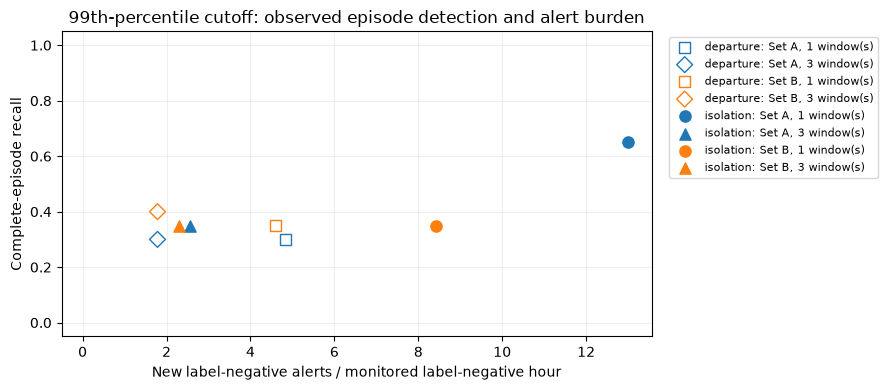

In [9]:
policy_rows = []
keys = ['calibration_seconds', 'population', 'method', 'feature_set', 'quantile', 'consecutive']
for identity, group in metrics.groupby(keys):
    total = group[['requested', 'decision_available', 'complete_episodes', 'detected_episodes',
                   'censored_positive_pieces', 'label_negative_alerts', 'unknown_label_alert_starts',
                   'monitored_negative_seconds', 'alert_negative_seconds', 'positive_bins_total',
                   'positive_bins_detected']].sum()
    matching = np.ones(len(events), dtype=bool)
    for key, value in zip(keys, identity):
        matching &= events[key].eq(value).to_numpy()
    delays = events.loc[matching & events.detected & events.complete & events.in_assessment, 'delay_s']
    negative_seconds = total.monitored_negative_seconds
    policy_rows.append({**dict(zip(keys, identity)), **total.to_dict(),
                        'availability': total.decision_available / total.requested,
                        'episode_recall': total.detected_episodes / total.complete_episodes,
                        'median_detected_delay_s': delays.median(),
                        'negative_alerts_per_hour': total.label_negative_alerts / (negative_seconds / 3600),
                        'negative_time_in_alert': total.alert_negative_seconds / negative_seconds,
                        'all_positive_bin_recall': total.positive_bins_detected / total.positive_bins_total})
policy_summary = pd.DataFrame(policy_rows)
main_policies = policy_summary.loc[policy_summary.calibration_seconds.eq(60)
                                  & policy_summary.population.eq('common')
                                  & policy_summary['quantile'].eq(.99)]
columns = ['method', 'feature_set', 'consecutive', 'availability', 'detected_episodes', 'complete_episodes',
           'episode_recall', 'median_detected_delay_s', 'negative_alerts_per_hour',
           'negative_time_in_alert', 'all_positive_bin_recall']
display(main_policies[columns].round(3))
display(availability.loc[availability.calibration_seconds.eq(60)].groupby('feature_set').agg(
    requested=('requested', 'sum'), available=('available', 'sum')))
print('Censored positive pieces per specification:', int(main_policies.censored_positive_pieces.iloc[0]))
display(primary.loc[primary.consecutive.eq(3)].groupby(
    ['method', 'family', 'feature_set'])[['complete_episodes', 'detected_episodes', 'label_negative_alerts']].sum())
print('Monitored label-negative exposure (hours):',
      round(main_policies.monitored_negative_seconds.iloc[0] / 3600, 3))
fig, ax = plt.subplots(figsize=(9, 4))
for row in main_policies.itertuples():
    marker = ('o' if row.consecutive == 1 else '^') if row.method == 'isolation' else (
        's' if row.consecutive == 1 else 'D')
    ax.scatter(row.negative_alerts_per_hour, row.episode_recall,
               color='tab:blue' if row.feature_set == 'A_level' else 'tab:orange', marker=marker,
               facecolors='none' if row.method == 'departure' else None, s=65,
               label=f'{row.method}: Set {row.feature_set[0]}, {row.consecutive} window(s)')
ax.set(title='99th-percentile cutoff: observed episode detection and alert burden',
       xlabel='New label-negative alerts / monitored label-negative hour',
       ylabel='Complete-episode recall', ylim=(-.05, 1.05))
ax.set_xlim(left=-.5)
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout(); fig.savefig(OUT / 'alert_tradeoffs.png', dpi=140, bbox_inches='tight'); plt.show()
policy_summary.to_csv(OUT / 'policy_summary.csv', index=False)

**Reading the policy comparison.** Shared vector availability is **4,864/5,150 = 94.45%**. There are **20 complete episodes** and **12 censored positive pieces** in six recordings; those pieces are outside the complete-episode denominator. Positive-bin coverage and recall still describe their observed portions.

For level-only Isolation Forest, the unchanged three-window rule reduces label-negative starts from **51 to 10**, and detected complete episodes from **13 to 7**. The detected-only median delay falls from 47 to 36 seconds because the detected population changes, not because waiting speeds up detection. Both Isolation Forest sets still miss all 12 complete valve episodes under this rule.

Compare the departure method's actual alert burden with its detections rather than treating removal of saturation as proof of a good policy. No acceptable alert budget has been established, and **3.923 monitored label-negative hours** cannot validate production reliability.

**New departure policy.** With three consecutive exceedances, Set A detects **6/20** complete episodes and Set B **8/20**, including **two complete valve1 episodes** for Set B. Both create **7 label-negative alert starts (1.78/hour)**. Their label-negative time in alert is **4.09% / 4.48%**, higher than Isolation Forest's **1.95% / 1.61%**. Fewer alert starts can coexist with longer alerts; neither method is uniformly superior.

Set B's episode count increases from 7 with immediate alerts to 8 with three windows. This is a consequence of the unchanged *new-alert-start* metric: in `other/5`, the immediate alert starts at **16:16:40**, before the annotated onset **16:16:48**, whereas the three-window alert starts at **16:16:50** and receives episode credit. Waiting did not uncover new evidence or improve early warning. The scored event count is sensitive to annotation boundaries and the declared matching rule; retain point coverage and alert exposure alongside it.

## 7. Inspect what a score and an alert mean on real recordings

The examples were chosen before detector evaluation: `valve1/1` and `other/10`, also used in Notebook 03. Shading is retrospective annotation, not an input. Feature traces retain physical units. The departure components can identify which measured departure drives that score; they do not identify a root cause. Isolation Forest's scalar score is shown without an unsupported sensor-causality explanation.

The alert strip uses the primary 99th-percentile cutoff and three consecutive windows. Alerts appear at their actual issue time. A score above its cutoff for one or two windows is not yet an alert under this policy.

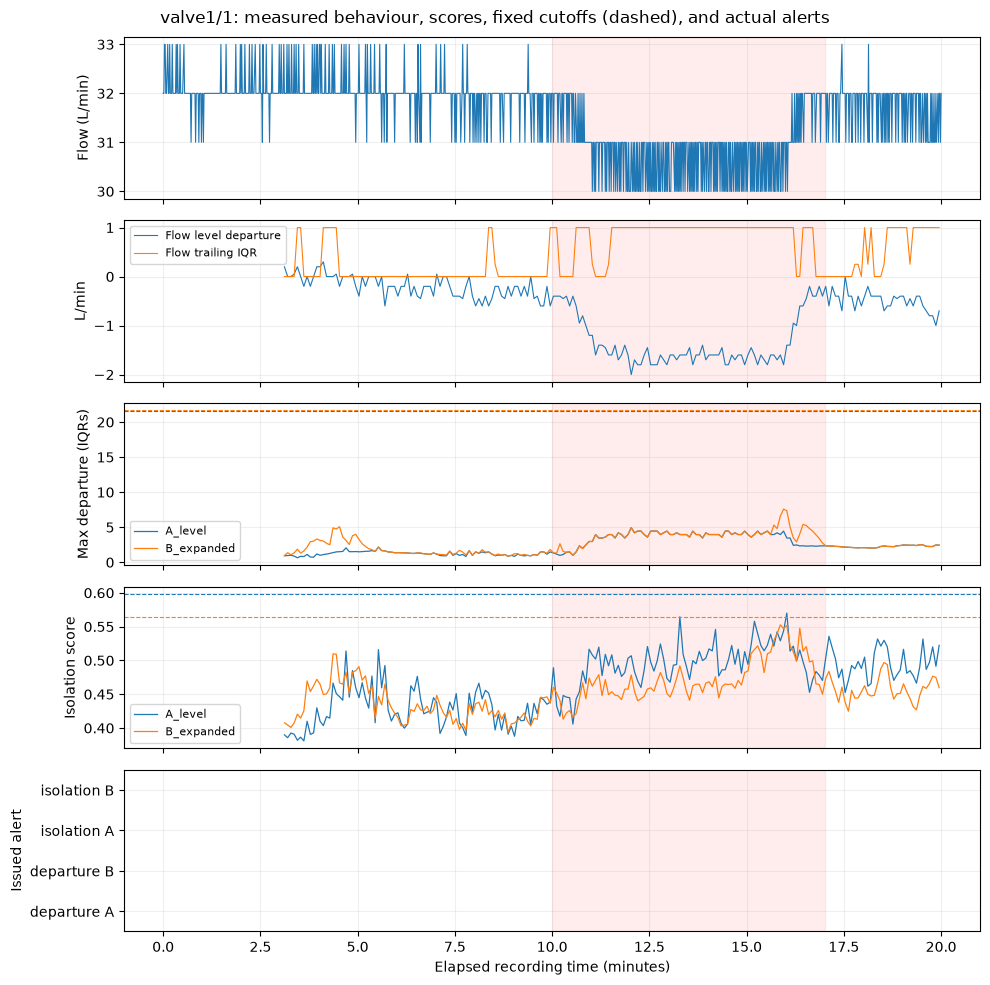

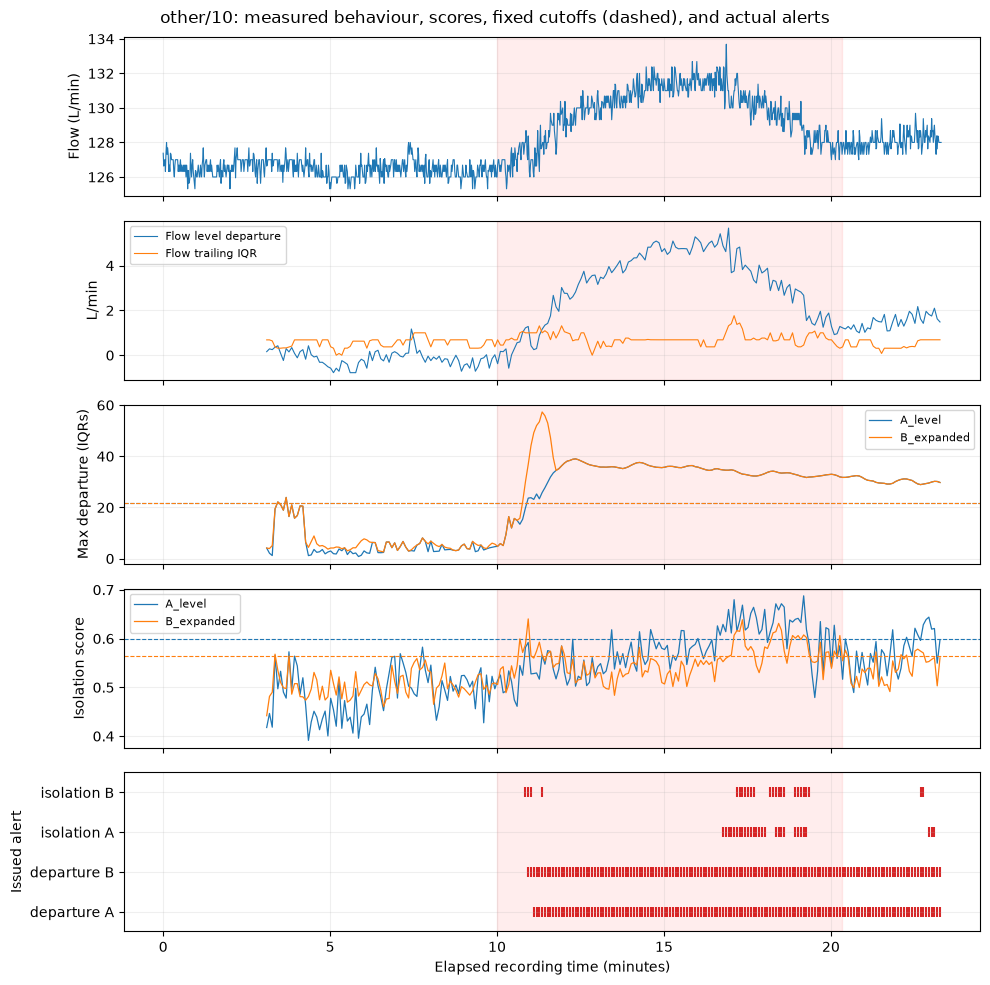

In [10]:
for name in ['valve1/1', 'other/10']:
    origin = recordings[name].timestamp.iloc[0]
    native = recordings[name].set_index('timestamp')
    value = features[60, name]
    minutes = (value.index - origin).total_seconds() / 60
    fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)
    axes[0].plot((native.index - origin).total_seconds() / 60, native['Volume Flow RateRMS'], linewidth=.8)
    axes[0].set_ylabel('Flow (L/min)')
    axes[1].plot(minutes, value['Volume Flow RateRMS__level'], label='Flow level departure', linewidth=.8)
    axes[1].plot(minutes, value['Volume Flow RateRMS__iqr'], label='Flow trailing IQR', linewidth=.8)
    axes[1].set_ylabel('L/min'); axes[1].legend(fontsize=8, loc='best')
    for ax, method in zip(axes[2:4], ['departure', 'isolation']):
        for set_name, colour in [('A_level', 'tab:blue'), ('B_expanded', 'tab:orange')]:
            selected = decisions.loc[decisions.recording_id.eq(name) & decisions.calibration_seconds.eq(60)
                & decisions.population.eq('common') & decisions['quantile'].eq(.99)
                & decisions.consecutive.eq(3) & decisions.method.eq(method) & decisions.feature_set.eq(set_name)]
            x = (selected.timestamp - origin).dt.total_seconds() / 60
            ax.plot(x, selected.score, color=colour, label=set_name, linewidth=.9)
            ax.axhline(selected.threshold.iloc[0], color=colour, linestyle='--', linewidth=.8)
        ax.set_ylabel('Max departure (IQRs)' if method == 'departure' else 'Isolation score'); ax.legend(fontsize=8, loc='best')
    lanes = [('departure', 'A_level'), ('departure', 'B_expanded'), ('isolation', 'A_level'), ('isolation', 'B_expanded')]
    for lane, (method, set_name) in enumerate(lanes):
        selected = decisions.loc[decisions.recording_id.eq(name) & decisions.calibration_seconds.eq(60)
            & decisions.population.eq('common') & decisions['quantile'].eq(.99)
            & decisions.consecutive.eq(3) & decisions.method.eq(method) & decisions.feature_set.eq(set_name)]
        active = selected.loc[selected.alarm.eq(1)]
        axes[4].scatter((active.timestamp - origin).dt.total_seconds() / 60,
                        np.full(len(active), lane), marker='|', s=50, color='tab:red')
    axes[4].set(yticks=range(4), yticklabels=[f'{method} {group[0]}' for method, group in lanes],
                xlabel='Elapsed recording time (minutes)', ylabel='Issued alert', ylim=(-.5, 3.5))
    for event in observed_episodes(native_labels[name]).itertuples():
        end = event.end if pd.notna(event.end) else event.last
        for ax in axes:
            ax.axvspan((event.start - origin).total_seconds() / 60,
                       (end - origin).total_seconds() / 60, color='red', alpha=.07)
    fig.suptitle(f'{name}: measured behaviour, scores, fixed cutoffs (dashed), and actual alerts')
    fig.tight_layout(); fig.savefig(OUT / (name.replace('/', '_') + '_decisions.png'), dpi=140); plt.show()

**Reading these examples.** Flow falls during the shaded interval in `valve1/1`. The unchanged Isolation Forest scores can rise without reaching their cutoffs. In `other/10`, the expanded Isolation Forest first alerts **51 seconds** after the first positive annotation, compared with **406 seconds** for the level-only version. That local benefit coexists with worse aggregate ranking for the expanded set.

The departure panels now show magnitudes without a ceiling. Their dashed cutoffs are fitted separately for each feature set; different score scales are expected. Read actual issued-alert strips to determine whether the score and persistence policy produce a detection. The flow panels explain one measured change, but scores use all configured features and do not identify a root cause.

The replacement departure method also misses `valve1/1` under the primary policy, despite useful ranking: its scores remain below approximately **21.6 IQRs**. In `other/10`, departure alerts start **66 seconds (Set A)** and **56 seconds (Set B)** after the annotated onset and remain active beyond the labelled interval. This illustrates why alert duration matters as well as alert count.

## 8. Gaps and unsupported calibration are monitoring outcomes

`other/2` contains a 247-second collection gap. The feature history resets, and a persistence alert has to rebuild its own run after a score becomes available. Its positive-label run is gap-censored; we do not infer an exact intervention onset through the gap. With 180-second local calibration, this recording fails the occupancy rule and its level-based detector vectors remain unavailable.

`other/13` fails both local calibration durations. Its lack of a complete detector vector remains a monitoring failure, not a correct negative prediction. Point metrics on available rows alone would conceal this limitation.

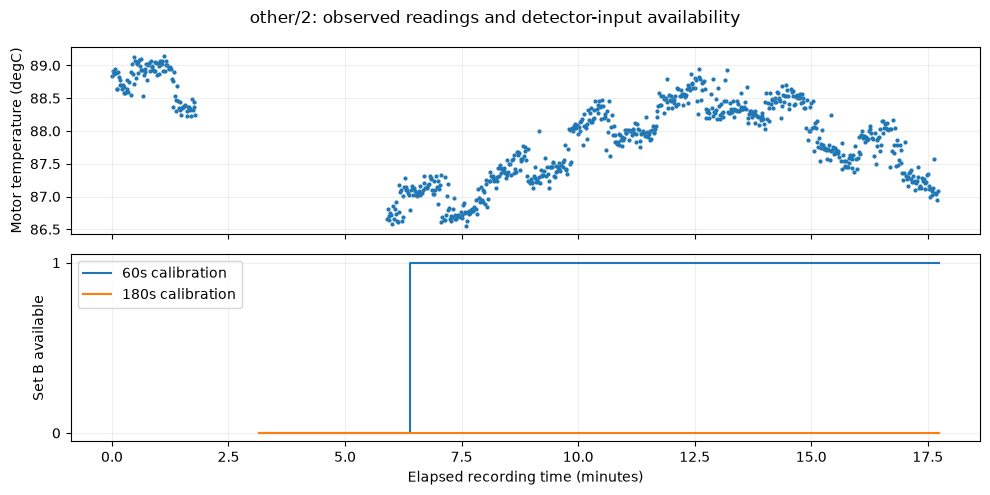

,recording_id,calibration_seconds,feature_set,requested,available,candidate_normal_rows
12,other/13,60,A_level,190,0,0
13,other/13,60,B_expanded,190,0,0
14,other/13,180,A_level,190,0,0
15,other/13,180,B_expanded,190,0,0
20,other/2,60,A_level,176,142,0
21,other/2,60,B_expanded,176,137,0
22,other/2,180,A_level,176,0,0
23,other/2,180,B_expanded,176,0,0


In [11]:
name = 'other/2'
origin = recordings[name].timestamp.iloc[0]
raw = recordings[name]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].scatter((raw.timestamp - origin).dt.total_seconds() / 60, raw.Temperature, s=4)
axes[0].set_ylabel('Motor temperature (degC)')
for duration, colour in [(60, 'tab:blue'), (180, 'tab:orange')]:
    values = features[duration, name]
    support = values.notna().all(axis=1)
    axes[1].step((values.index - origin).total_seconds() / 60, support.astype(int),
                 where='post', label=f'{duration}s calibration', color=colour)
axes[1].set(xlabel='Elapsed recording time (minutes)', ylabel='Set B available', yticks=[0, 1])
axes[1].legend(); fig.suptitle('other/2: observed readings and detector-input availability')
fig.tight_layout(); fig.savefig(OUT / 'gap_and_calibration.png', dpi=140); plt.show()
display(availability.loc[availability.recording_id.isin(['other/2', 'other/13']),
    ['recording_id', 'calibration_seconds', 'feature_set', 'requested', 'available', 'candidate_normal_rows']])

## 9. Predeclared sensitivity checks; no selection of the best-looking setting

Cutoff percentile, alert persistence and local calibration duration affect different parts of the experiment. We show all combinations rather than choosing them using event recall. The 60/180-second comparison below also evaluates ranking on their **intersection of eligible timestamps**; otherwise a calibration failure could appear to improve results merely by removing a difficult recording.

Isolation Forest is repeated with seeds 17 and 91 as a stability check. Every seed has its own cutoff from the same cutoff-calibration recordings. We report the range, not the best seed. No detector is refitted using assessment labels.

In [12]:
display(policy_summary.loc[policy_summary.population.eq('common'),
    ['calibration_seconds', 'method', 'feature_set', 'quantile', 'consecutive', 'availability',
     'episode_recall', 'negative_alerts_per_hour', 'negative_time_in_alert']].round(3))
calibration_comparison = []
for name in development_ids:
    shared = features[60, name].notna().all(axis=1) & features[180, name].notna().all(axis=1)
    for set_name in feature_sets:
        for method in ['departure', 'isolation']:
            for duration in [60, 180]:
                scores = scoring[duration, name, set_name, method]
                summary = point_metrics(window_labels[name].label, scores,
                                        pd.Series(0., index=scores.index), shared)
                calibration_comparison.append({'recording_id': name, 'method': method,
                    'feature_set': set_name, 'calibration_seconds': duration,
                    'average_precision': summary.average_precision, 'common': summary.common})
calibration_comparison = pd.DataFrame(calibration_comparison)
display(calibration_comparison.groupby(['method', 'feature_set', 'calibration_seconds']).agg(
    available_recordings=('average_precision', 'count'), mean_AP=('average_precision', 'mean'),
    common_bins=('common', 'sum')).round(3))
calibration_comparison.to_csv(OUT / 'calibration_paired_ranking.csv', index=False)

,calibration_seconds,method,feature_set,quantile,consecutive,availability,episode_recall,negative_alerts_per_hour,negative_time_in_alert
0,60,departure,A_level,0.95,1,0.944,0.45,8.923,0.101
1,60,departure,A_level,0.95,3,0.944,0.45,4.079,0.081
2,60,departure,A_level,0.99,1,0.944,0.30,4.844,0.051
3,60,departure,A_level,0.99,3,0.944,0.30,1.785,0.041
4,60,departure,B_expanded,0.95,1,0.944,0.50,9.178,0.106
5,60,departure,B_expanded,0.95,3,0.944,0.45,4.844,0.085
6,60,departure,B_expanded,0.99,1,0.944,0.35,4.589,0.054
7,60,departure,B_expanded,0.99,3,0.944,0.40,1.785,0.045
8,60,isolation,A_level,0.95,1,0.944,0.80,19.120,0.092
9,60,isolation,A_level,0.95,3,0.944,0.40,4.844,0.054


available_recordings  mean_AP  \
method    feature_set calibration_seconds                                  
departure A_level     60                                     24    0.860   
                      180                                    24    0.866   
          B_expanded  60                                     24    0.848   
                      180                                    24    0.855   
isolation A_level     60                                     24    0.807   
                      180                                    24    0.851   
          B_expanded  60                                     24    0.769   
                      180                                    24    0.776   

                                           common_bins  
method    feature_set calibration_seconds               
departure A_level     60                        4689.0  
                      180                       4689.0  
          B_expanded  60                        4689.0  
                      180                       4689.0  
isolation A_level     60                        4689.0  
                      180                       4689.0  
          B_expanded  60                        4689.0  
                      180                       4689.0

In [13]:
seed_rows = []
for seed in experiment['sensitivity_seeds']:
    for fold in range(3):
        cutoff_ids = folds.index[folds.fold.eq((fold + 2) % 3)].tolist()
        assess_ids = folds.index[folds.fold.eq(fold)].tolist()
        for set_name, columns in feature_sets.items():
            fit_values = training_values[60, fold, set_name]
            cutoff_values = pd.concat([features[60, name].loc[reference_masks[60, name], columns]
                                       for name in cutoff_ids])
            forest = IsolationForest(n_estimators=experiment['isolation_trees'],
                                     max_samples=experiment['isolation_max_samples'],
                                     random_state=seed, n_jobs=1).fit(fit_values)
            threshold = calibrate_threshold(pd.Series(-forest.score_samples(cutoff_values)), .99).threshold
            for name in assess_ids:
                values = features[60, name][columns]
                common = features[60, name].notna().all(axis=1)
                scores = pd.Series(np.nan, index=values.index)
                if common.any():
                    scores.loc[common] = -forest.score_samples(values.loc[common])
                alarm = causal_alerts(scores, threshold, 3, frequency=step)
                point = point_metrics(window_labels[name].label, scores, alarm.alarm)
                episode, _ = episode_metrics(native_labels[name], alarm, frequency=step, max_gap=settings['gap_threshold'])
                seed_rows.append({'seed': seed, 'feature_set': set_name, 'recording_id': name,
                                  'threshold': threshold, **point.to_dict(), **episode.to_dict()})
seed_metrics = pd.DataFrame(seed_rows)
primary_seed = primary.loc[primary.method.eq('isolation') & primary.consecutive.eq(3)].assign(
    seed=experiment['primary_seed'])
seed_metrics = pd.concat([seed_metrics, primary_seed], ignore_index=True)
seed_summary = seed_metrics.groupby(['seed', 'feature_set']).agg(
    mean_AP=('average_precision', 'mean'), detected=('detected_episodes', 'sum'),
    complete=('complete_episodes', 'sum'), negative_alerts=('label_negative_alerts', 'sum'),
    negative_seconds=('monitored_negative_seconds', 'sum'))
seed_summary['episode_recall'] = seed_summary.detected / seed_summary.complete
seed_summary['negative_alerts_per_hour'] = seed_summary.negative_alerts / (seed_summary.negative_seconds / 3600)
display(seed_summary[['mean_AP', 'episode_recall', 'negative_alerts_per_hour']].round(3))
seed_metrics.to_csv(OUT / 'isolation_seed_sensitivity.csv', index=False)

mean_AP  episode_recall  negative_alerts_per_hour
seed feature_set                                                   
17   A_level        0.789            0.35                     1.530
     B_expanded     0.752            0.35                     0.765
42   A_level        0.811            0.35                     2.549
     B_expanded     0.771            0.35                     2.294
91   A_level        0.782            0.35                     2.294
     B_expanded     0.730            0.30                     2.294

**Observed sensitivity.** On the same **24 available recordings and 4,689 pure-label common bins**, increasing calibration from 60 to 180 seconds raises level-only Isolation Forest mean AP from **0.807 to 0.851**; expanded-model AP changes from **0.769 to 0.776**. This is conditional on shared support: the 180-second protocol loses `other/2`, and neither protocol supports `other/13`. A longer initial information budget is not a free improvement.

Across the three declared seeds, level-only mean AP ranges **0.782–0.811** and expanded mean AP **0.730–0.771**. The primary three-window policy detects 7/20 complete episodes for every level-only seed and 6–7/20 for expanded features. Label-negative alert counts also vary. We retain seed 42 as declared; the smaller count from another seed is not a reason to select it.

## 10. Findings and handover

The original empirical-rarity score is replaced because it could not exceed its calibrated cutoff. The current maximum median/IQR departure is an interpretable individual-feature comparator; Isolation Forest remains the joint-feature comparator. This revision preserves folds, fitting information, features, cutoff percentiles and alert rules.

**Executed result:** the replacement improves mean per-recording ranking to **0.856 / 0.847** for Set A / B and removes the impossible-to-exceed ceiling. Under the unchanged primary three-window policy it detects **6/20 / 8/20** complete episodes, with **7 label-negative alert starts** for each set. Expanded departures detect two valve1 episodes; ten complete valve episodes remain missed. Label-negative time in alert rises to **4.09% / 4.48%**, so fewer alert starts do not establish lower burden on every measure.

Isolation Forest scores, cutoffs and decisions are identical to the previous execution. Feature availability, support reasons and local calibration estimates are also unchanged for the native SKAB timestamp resolution. The gap correction matters when timestamps use seconds, milliseconds or microseconds; focused tests now cover those representations.

The earlier empirical-rarity result remains documented in Git history and in the failure explanation above. This run compares the replacement against the unchanged forest; it does not select a production detector. Read ranking, availability, episode matching, alert duration and alert starts together.

| Component | Next use | Limitation |
|---|---|---|
| Eight level departures | Keep as the primary feature comparator | Short initial calibration may not represent later ordinary behaviour |
| All 19 features | Retain as an alternative for controlled comparison | More descriptions can add ordinary cycling and drift as well as useful changes |
| Median/IQR departure components | Inspect which features drive a large score | Marginal distances do not model relationships; pooled spread may transfer poorly |
| Isolation Forest | Keep the unchanged joint-feature benchmark | Primary persistence policy still misses all complete valve episodes |
| Three-window persistence | Keep the explicit burden/detection comparison | Cannot accumulate moderate deviations below the cutoff |
| Support rules | Preserve unavailable outcomes | Zero spread cannot supply a scaled score; unsupported recordings remain monitoring failures |

**Next scientific question:** does ordinary variability differ enough between recordings to make one pooled score/cutoff inappropriate? Investigate reference transfer before changing regimes, feature sets or alert policies. Intervention family is not automatically an operational predictor.

Keep all eight reserved recordings closed until the protocol is frozen. Training annotations identify candidate-normal examples; deployment without such evidence is a separate experiment. One testbed, short dependent recordings and incomplete incident boundaries do not establish failure prediction or cross-industry performance.

In [14]:
# Provenance describes exactly which data, definitions and software produced the outputs.
source_files = [record for record in settings['files'] if record['partition'] != 'reserved_test']
provenance = {
    'source_commit': settings['source_commit'], 'opened_files': source_files,
    'model_population': development_ids, 'reserved_files_opened': [],
    'normal_file_used_for_models': False, 'feature_sets': feature_sets,
    'score_revision': 'maximum_median_iqr_departure_v1',
    'departure_definition': 'max(abs(value - fitted_median) / fitted_iqr)',
    'zero_iqr_policy': 'Unsupported component and complete-vector score; no epsilon or fallback',
    'timestamp_gap_check': 'Elapsed timedeltas; independent of datetime storage resolution',
    'experiment': experiment, 'local_calibration': baseline_settings,
    'feature_settings': feature_settings,
    'versions': {package: version(package) for package in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']},
    'source_sha256': {path: hashlib.sha256((ROOT / path).read_bytes()).hexdigest() for path in [
        'src/ts_anomaly/features.py', 'src/ts_anomaly/baselines.py', 'src/ts_anomaly/detection.py',
        'src/ts_anomaly/evaluation.py', 'configs/skab.json']},
    'limits': ['Development comparisons only; no final-test claims.',
               'One physical testbed; recordings are not independent industrial assets.',
               'Candidate-normal training uses annotations; local calibration does not.',
               'No point adjustment; gap-censored episodes are not complete incidents.']}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))
assert set(provenance['model_population']).isdisjoint(reserved_ids)
print('Complete per-recording scores, decisions, components, support and provenance:', OUT)
print('Reserved recording values were not requested by the data loader.')

Complete per-recording scores, decisions, components, support and provenance: /Users/lilidopidze/Documents/ChatGPT/Anomaly Detection/implementation/scientific-foundation/outputs/skab_detection
Reserved recording values were not requested by the data loader.


### Methodological references

- [Official SKAB source](https://github.com/waico/SKAB/tree/b2c0d46c2971dcbfe71e26087b6d231998bb91c2): laboratory data and annotations; the project split and alert policies here are our choices.
- [scikit-learn: grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data): keeping groups separate addresses row-level leakage. It does not prove independence between runs on the same machine.
- [scikit-learn: novelty and outlier detection](https://scikit-learn.org/stable/modules/outlier_detection.html): reference-population assumptions.
- [scikit-learn: Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html): algorithm, continuous scores and the distinction from its binary cutoff.
- [scikit-learn: average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html): ranking metric definition.
- [Kim et al., *Towards a Rigorous Evaluation of Time-series Anomaly Detection*, AAAI 2022](https://arxiv.org/abs/2109.05257): point-adjustment can inflate apparent detection quality. We preserve actual point decisions and alert times.

The median/IQR departure formula, support rules, folds, quantiles and consecutive-window policies are transparent experimental specifications, not claimed universal best practices or probabilistic guarantees.